[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/03-math/04_vectors.ipynb)

*Math for Data Science & ML · Notebook 4 of 10*

# Vectors

Arrows and lists of numbers: adding and scaling, length, distance, the dot product, angles, cosine similarity and projections — how ML represents every data point.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A vector is an arrow, and also a list of numbers. The dot product measures how much two arrows agree.

**What interviewers really test here:** Dot product, cosine similarity, norms and projections.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. What is a vector? *(Basics)*
- [ ] 2. Adding and scaling vectors *(Basics)*
- [ ] 3. What vector operations mean for data *(Basics)*
- [ ] 4. Length and distance *(Core)*
- [ ] 5. The dot product and angles *(Core)*
- [ ] 6. The dot product and angle, worked *(Core)*
- [ ] 7. Three ways to measure length *(Core)*
- [ ] 8. Projection and the cross product *(Advanced)*
- [ ] 9. Independence, span and basis *(Advanced)*
- [ ] 10. Similarity search, the idea behind embeddings *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Definitions

A **vector** in ℝⁿ is an ordered n-tuple v = (v₁, …, vₙ). A **scalar** is a single number. Vectors are usually written as columns. The **zero vector** has all components 0; **standard basis vectors** e₁ = (1, 0, …), e₂ = (0, 1, …) point along the axes, and every vector is a linear combination of them: v = v₁e₁ + … + vₙeₙ.

### Operations

| Operation | Formula | Result |
| --- | --- | --- |
| Addition | (u + v)ᵢ = uᵢ + vᵢ | vector |
| Scalar multiple | (cv)ᵢ = c·vᵢ | vector |
| Dot product | u·v = Σ uᵢvᵢ = ‖u‖‖v‖cos θ | scalar |
| Norm (L2) | ‖v‖ = √(v·v) | scalar ≥ 0 |
| L1 norm | ‖v‖₁ = Σ\|vᵢ\| | scalar |
| Projection | proj\_v u = (u·v / v·v) v | vector |
| Cross product (ℝ³) | u × v ⟂ u and v, ‖u × v‖ = ‖u‖‖v‖ sin θ | vector |
| Hadamard | (u ⊙ v)ᵢ = uᵢvᵢ | vector |

### Key properties

- Dot product is commutative and distributive: u·(v + w) = u·v + u·w.
- **Cauchy–Schwarz**: |u·v| ≤ ‖u‖‖v‖ — so cosine similarity is always in [−1, 1].
- **Triangle inequality**: ‖u + v‖ ≤ ‖u‖ + ‖v‖.
- u ⟂ v ⇔ u·v = 0. A set of mutually perpendicular unit vectors is **orthonormal**.
- Vectors are **linearly independent** if none is a combination of the others; n independent vectors in ℝⁿ form a **basis**. The set of all their combinations is their **span**.

### Distances used in ML

| Distance | Formula | Used in |
| --- | --- | --- |
| Euclidean (L2) | √Σ(pᵢ − qᵢ)² | k-NN, k-means |
| Manhattan (L1) | Σ\|pᵢ − qᵢ\| | robust distance, grids, Lasso penalty |
| Cosine distance | 1 − cos θ | text, embeddings, recommendation |
| Hamming | number of positions that differ | binary / categorical codes |



Distances are sensitive to scale: a feature measured in thousands dominates one measured in units, so scale features first.

---
# Part 2: Lessons, step by step

## Lesson 1: What is a vector?

*Level: Basics*

A **vector** is an ordered list of numbers. You can picture it two ways:




- As an **arrow** from the origin: v = [3, 2] means "3 right, 2 up". It has a direction and a length.
- As a **data point**: a house = [size 120, rooms 3, age 15]. Every row of a dataset is a vector.



The number of components is the **dimension**. We can't draw 300-dimensional vectors, but the math is identical to 2-D, so we build intuition with arrows on paper.



In Python: `v = np.array([3, 2])`.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

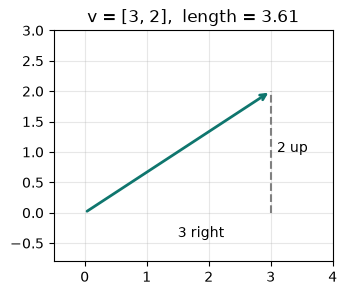

In [2]:
def vector_demo():
    v = np.array([3, 2])
    length = np.linalg.norm(v)
    fig, ax = plt.subplots(figsize=(3.6, 3))
    ax.annotate("", xy=(3, 2), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="#0f766e", lw=2))
    ax.plot([3, 3], [0, 2], "--", color="gray")
    ax.text(1.5, -0.4, "3 right")
    ax.text(3.1, 1, "2 up")
    ax.set_xlim(-0.5, 4)
    ax.set_ylim(-0.8, 3)
    ax.set_title(f"v = [3, 2],  length = {length:.2f}")
    ax.grid(alpha=0.3)


vector_demo()

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q4](#q4), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 2: Adding and scaling vectors

*Level: Basics*

**Add** component by component: [1, 2] + [3, 1] = [4, 3]. As arrows: put the second arrow's tail on the first arrow's tip ("tip to tail"); the sum goes from start to finish.



**Scale** by multiplying every component: 2·[1, 2] = [2, 4] (twice as long, same direction); −1·v points the opposite way.



A **linear combination** c₁v₁ + c₂v₂ mixes vectors with weights — every prediction of a linear model is a linear combination of features.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

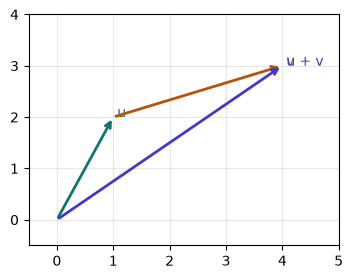

In [3]:
def arrows(ax, vecs, labels, colors, origin=(0, 0)):
    for (x, y), lab, c in zip(vecs, labels, colors):
        ax.annotate("", xy=(origin[0] + x, origin[1] + y), xytext=origin, arrowprops=dict(arrowstyle="->", color=c, lw=2))
        ax.text(origin[0] + x, origin[1] + y, " " + lab, color=c)


def add_demo():
    u, v = np.array([1, 2]), np.array([3, 1])
    total = u + v
    fig, ax = plt.subplots(figsize=(4, 3))
    arrows(ax, [u], ["u"], ["#0f766e"])
    arrows(ax, [v], ["v"], ["#b45309"], origin=tuple(u))
    arrows(ax, [total], ["u + v"], ["#4338ca"])
    ax.set_xlim(-0.5, 5)
    ax.set_ylim(-0.5, 4)
    ax.grid(alpha=0.3)


add_demo()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q16](#q16), [Q9](#q9), [Q11](#q11). Try one now, or carry on and do them in Part 3.

## Lesson 3: What vector operations mean for data

*Level: Basics*

Treat each house as a vector: [size, rooms, age].



| Operation | Example | Meaning |
| --- | --- | --- |
| Subtract | [120, 3, 5] − [100, 2, 15] = [20, 1, −10] | how they differ |
| Add, then divide | mean of two houses = [110, 2.5, 10] | the average house (a k-means centre) |
| Scale | 0.5 × [120, 3, 5] = [60, 1.5, 2.5] | shrink all features together |
| Dot with weights | [2, 10, −1]·[120, 3, 5] = 265 | a linear model's prediction |



**Sizes must match.** Adding a 3-feature house to a 2-feature one is meaningless, and it's the most common shape error in practice.



A word embedding, an image and a customer are all vectors. Everything you learn here works in any number of dimensions, even though we only draw two.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [4]:
def house_vectors():
    a = np.array([120.0, 3, 5])
    b = np.array([100.0, 2, 15])
    difference = a - b
    average = (a + b) / 2
    half = 0.5 * a
    weights = np.array([2.0, 10, -1])
    prediction = weights @ a


house_vectors()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q9](#q9), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 4: Length and distance

*Level: Core*

The **length** (norm) of v = [3, 4] comes from Pythagoras: ‖v‖ = √(3² + 4²) = 5. In any dimension: ‖v‖ = √(v₁² + v₂² + … + vₙ²).



The **distance** between points p and q is the length of p − q. This is **Euclidean** distance (as the crow flies); **Manhattan** distance adds |differences| instead (along a street grid).



Dividing a vector by its length gives a **unit vector** (length 1) — pure direction. Distances power k-nearest-neighbours and k-means clustering; that's why features should be on similar scales (min-max scaling).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

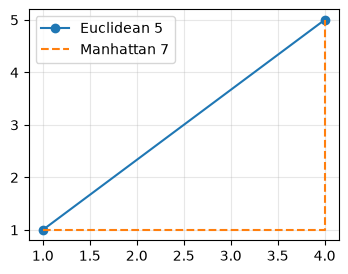

In [5]:
def distance_demo():
    p, q = np.array([1, 1]), np.array([4, 5])
    euclid = np.linalg.norm(p - q)
    manhattan = np.abs(p - q).sum()
    fig, ax = plt.subplots(figsize=(4, 3))
    ax.plot(*zip(p, q), "o-", label=f"Euclidean {euclid:.0f}")
    ax.plot([1, 4, 4], [1, 1, 5], "--", label=f"Manhattan {manhattan}")
    ax.legend()
    ax.grid(alpha=0.3)


distance_demo()

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q18](#q18), [Q10](#q10), [Q12](#q12). Try one now, or carry on and do them in Part 3.

## Lesson 5: The dot product and angles

*Level: Core*

The **dot product** multiplies matching components and adds: [1, 2]·[3, 1] = 1·3 + 2·1 = 5. It is the most important operation in ML.



Geometrically: **u·v = ‖u‖‖v‖ cos θ**, where θ is the angle between them. So:



| u·v | Angle | Meaning |
| --- | --- | --- |
| &gt; 0 | &lt; 90° | point the same-ish way |
| = 0 | 90° | **perpendicular** (orthogonal) |
| &lt; 0 | &gt; 90° | point opposite-ish ways |



**Cosine similarity** = u·v / (‖u‖‖v‖) ignores length and compares direction — search engines and ChatGPT-style embeddings use it to find similar text. A **neuron** is a dot product plus a bias: w·x + b.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

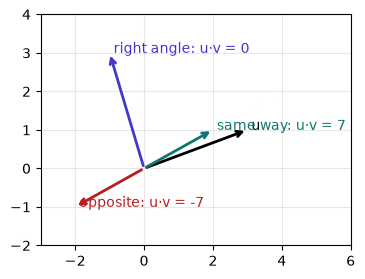

In [6]:
def arrows(ax, vecs, labels, colors, origin=(0, 0)):
    for (x, y), lab, c in zip(vecs, labels, colors):
        ax.annotate("", xy=(origin[0] + x, origin[1] + y), xytext=origin, arrowprops=dict(arrowstyle="->", color=c, lw=2))
        ax.text(origin[0] + x, origin[1] + y, " " + lab, color=c)


def dot_demo():
    u = np.array([3, 1])
    vs = {"same way": np.array([2, 1]), "right angle": np.array([-1, 3]), "opposite": np.array([-2, -1])}
    results = {}
    for name, v in vs.items():
        results[name] = int(u @ v)
    fig, ax = plt.subplots(figsize=(4, 3))
    arrows(ax, [u] + list(vs.values()), ["u"] + [f"{k}: u·v = {results[k]}" for k in vs], ["black", "#0f766e", "#4338ca", "#b91c1c"])
    ax.set_xlim(-3, 6)
    ax.set_ylim(-2, 4)
    ax.grid(alpha=0.3)


dot_demo()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q13](#q13), [Q14](#q14), [Q8](#q8), [Q17](#q17), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 6: The dot product and angle, worked

*Level: Core*

u = (3, 4) and v = (4, 3).



1. **Dot product:** 3·4 + 4·3 = 24.
2. **Lengths:** ‖u‖ = √(9 + 16) = 5 and ‖v‖ = 5.
3. **Cosine:** 24 / (5 × 5) = 0.96.
4. **Angle:** arccos(0.96) = **16.26°**. They point in similar directions.



| Cosine | Angle | Meaning |
| --- | --- | --- |
| 1 | 0° | same direction |
| 0 | 90° | unrelated (perpendicular) |
| −1 | 180° | opposite |



#### Why u·v = ‖u‖‖v‖cos θ?



Think of shadows. The dot product is the length of u's shadow on v, multiplied by v's length. When they're perpendicular there's no shadow, so the result is 0.



**Length itself comes from the dot product:** v·v = ‖v‖². That's why squared errors and vector lengths look alike.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [7]:
def dot_worked():
    u, v = np.array([3.0, 4.0]), np.array([4.0, 3.0])
    dot = u @ v
    lengths = (np.linalg.norm(u), np.linalg.norm(v))
    cosine = dot / (lengths[0] * lengths[1])
    degrees = math.degrees(math.acos(cosine))
    self_dot = v @ v


dot_worked()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q13](#q13), [Q14](#q14), [Q8](#q8), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 7: Three ways to measure length

*Level: Core*

For v = (3, −4):



| Norm | Formula | Value | Think of it as |
| --- | --- | --- | --- |
| L1 (Manhattan) | \|3\| + \|−4\| | 7 | walking a street grid |
| L2 (Euclidean) | √(9 + 16) | 5 | straight line |
| L∞ (max) | max(3, 4) | 4 | the single largest change |



The chart draws all points with length 1 under each norm. L2 gives a circle, L1 a diamond, and L∞ a square.



#### Why ML cares



- **L2 penalty (Ridge):** shrinks all weights smoothly.
- **L1 penalty (Lasso):** sets some weights to exactly 0. The diamond's corners lie on the axes, where a weight is 0.
- **Distances:** L1 is less sensitive to one huge difference, since it isn't squared.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

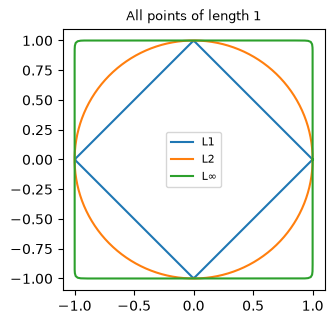

In [8]:
def norm_shapes():
    v = np.array([3.0, -4.0])
    l1 = np.abs(v).sum()
    l2 = math.sqrt((v ** 2).sum())
    linf = np.abs(v).max()
    t = np.linspace(0, 2 * np.pi, 400)
    circle = np.column_stack([np.cos(t), np.sin(t)])
    fig, ax = plt.subplots(figsize=(3.4, 3.4))
    for p, name in [(1, "L1"), (2, "L2"), (50, "L∞")]:
        scale = (np.abs(circle) ** p).sum(axis=1) ** (1 / p)
        ax.plot(circle[:, 0] / scale, circle[:, 1] / scale, label=name)
    ax.set_aspect("equal")
    ax.legend(fontsize=8)
    ax.set_title("All points of length 1", fontsize=9)


norm_shapes()

**✏️ Your turn:** you now have what you need for [Q3](#q3), [Q5](#q5), [Q6](#q6), [Q4](#q4), [Q18](#q18), [Q10](#q10). Try one now, or carry on and do them in Part 3.

## Lesson 8: Projection and the cross product

*Level: Advanced*

The **projection** of u onto v is u's "shadow" on the line of v: proj = (u·v / v·v)·v. What's left over, u − proj, is perpendicular to v. Projection is the heart of linear regression (projecting the targets onto the space of features) and of PCA (projecting data onto its main direction).



In 3-D only, the **cross product** u × v gives a vector perpendicular to both, with length equal to the area of the parallelogram they span — used in graphics and physics more than ML.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

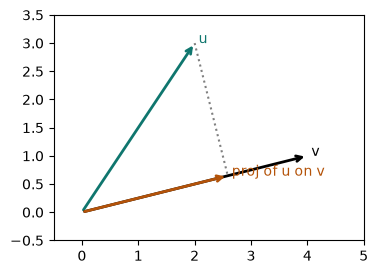

In [9]:
def arrows(ax, vecs, labels, colors, origin=(0, 0)):
    for (x, y), lab, c in zip(vecs, labels, colors):
        ax.annotate("", xy=(origin[0] + x, origin[1] + y), xytext=origin, arrowprops=dict(arrowstyle="->", color=c, lw=2))
        ax.text(origin[0] + x, origin[1] + y, " " + lab, color=c)


def projection_demo():
    u, v = np.array([2, 3]), np.array([4, 1])
    proj = (u @ v) / (v @ v) * v
    residual = u - proj
    check = residual @ v
    fig, ax = plt.subplots(figsize=(4, 3))
    arrows(ax, [u, v, proj], ["u", "v", "proj of u on v"], ["#0f766e", "black", "#b45309"])
    ax.plot([u[0], proj[0]], [u[1], proj[1]], ":", color="gray")
    ax.set_xlim(-0.5, 5)
    ax.set_ylim(-0.5, 3.5)
    ax.set_aspect("equal")


projection_demo()

**✏️ Your turn:** you now have what you need for [Q15](#q15), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 9: Independence, span and basis

*Level: Advanced*

#### Span: everywhere you can reach



Combining vectors with weights, c₁v₁ + c₂v₂, reaches a set of points called their **span**.



- (1, 0) and (0, 1) reach every point of the plane.
- (1, 2) and (2, 4) only reach one line, since the second is just 2 × the first.



#### Linear independence



Vectors are **independent** if none can be built from the others. (1, 2) and (2, 4) are dependent, so the second adds no new direction.



**In data:** a "price in rupees" column and a "price in dollars" column are dependent. The second adds no information, and it causes unstable regression.



#### Basis: a coordinate system



A basis is a minimal set of independent vectors that reaches everything. The point (3, 5) can be written in two ways:



- Using (1, 0), (0, 1): 3(1, 0) + 5(0, 1)
- Using (1, 1), (1, −1): 4(1, 1) − 1(1, −1) = (3, 5)



It's the same point with different coordinates. **PCA is choosing a better basis** for your data.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [10]:
def basis_demo():
    dependent_rank = np.linalg.matrix_rank([[1, 2], [2, 4]])
    independent_rank = np.linalg.matrix_rank([[1, 0], [0, 1]])
    new_basis = np.array([[1, 1], [1, -1]]).T
    coordinates = np.linalg.solve(new_basis, [3, 5])
    rebuilt = coordinates[0] * np.array([1, 1]) + coordinates[1] * np.array([1, -1])


basis_demo()

**✏️ Your turn:** you now have what you need for [Q16](#q16), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 10: Similarity search, the idea behind embeddings

*Level: Advanced*

Modern AI turns text into vectors called **embeddings**, placing similar meanings close together. Finding similar items is then simple maths.



#### Cosine or distance?



Compare a = (1, 2) with b = (2, 4), a longer vector in the same direction.



- Euclidean distance: √(1 + 4) = 2.236, so they seem different.
- Cosine similarity: 10 / (2.236 × 4.472) = 1, so they seem identical.



A long document and a short one on one topic have different lengths and the same direction, so cosine suits text.



#### A speed trick



If all vectors are scaled to length 1, the dot product **is** the cosine. So similarity against a million items becomes one matrix–vector multiply. That's how retrieval in a RAG system works, and vector databases add indexes to make it faster still.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [11]:
def similarity_search():
    words = ["king", "queen", "apple", "banana"]
    vectors = np.array([[0.9, 0.8, 0.1], [0.85, 0.9, 0.15], [0.1, 0.2, 0.9], [0.15, 0.1, 0.95]])
    unit = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)
    query = unit[0]
    scores = (unit @ query).round(3)
    ranked = [words[i] for i in np.argsort(-scores)]
    a, b = np.array([1.0, 2.0]), np.array([2.0, 4.0])
    distance = np.linalg.norm(a - b)
    cosine = a @ b / (np.linalg.norm(a) * np.linalg.norm(b))


similarity_search()

**✏️ Your turn:** you now have what you need for [Q20](#q20), [Q14](#q14), [Q12](#q12), [Q11](#q11). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. Add Two Vectors

🟢 Warm-up · *Tip to tail*

Return u + v.

**Examples**

- `u = [1, 2], v = [3, 1]` → `[4, 3]`
- `u = [1, -1, 0], v = [2, 2, 2]` → `[3, 1, 2]`

In [ ]:
def add(u, v):
    """
    Return u + v.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(add, [
    (([1, 2], [3, 1]), [4, 3]),
    (([1, -1, 0], [2, 2, 2]), [3, 1, 2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add matching components one by one.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.array(u) + np.array(v)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Add matching components one by one.

```python
def add(u, v):
    out = []
    for i in range(len(u)):
        out.append(u[i] + v[i])
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.array(u) + np.array(v)`.

```python
def add(u, v):
    return np.array(u) + np.array(v)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add matching components one by one. That costs O(n) time and O(n) space."

"I can do better: `np.array(u) + np.array(v)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/add-two-vectors)

<a id="q2"></a>
### Q2. Scale a Vector

🟢 Warm-up · *Scalar multiplication*

Return k·v.

**Examples**

- `k = 3, v = [1, -2]` → `[3, -6]`
- `k = 0.5, v = [4, 2, 6]` → `[2.0, 1.0, 3.0]`

In [ ]:
def scale(k, v):
    """
    Return k·v.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(scale, [
    ((3, [1, -2]), [3, -6]),
    ((0.5, [4, 2, 6]), [2.0, 1.0, 3.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply every component by k.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`k * np.array(v)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Multiply every component by k.

```python
def scale(k, v):
    return [k * x for x in v]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `k * np.array(v)`.

```python
def scale(k, v):
    return k * np.array(v)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply every component by k. That costs O(n) time and O(n) space."

"I can do better: `k * np.array(v)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/scale-a-vector)

<a id="q3"></a>
### Q3. Length of a Vector

🟢 Warm-up · *Norm ‖v‖*

Return ‖v‖ = √(v₁² + v₂² + …), rounded to 4 decimals.

**Examples**

- `v = [3, 4]` → `5.0`
- `v = [1, 1, 1]` → `1.7321`
- `v = [0, 0]` → `0.0`

In [ ]:
def length(v):
    """
    Return ‖v‖ = √(v₁² + v₂² + …), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(length, [
    (([3, 4],), 5.0),
    (([1, 1, 1],), 1.7321),
    (([0, 0],), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Pythagoras: square, add, square-root.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.norm(v)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Pythagoras: square, add, square-root.

```python
def length(v):
    total = 0
    for x in v:
        total += x * x
    return round(math.sqrt(total), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.linalg.norm(v)`.

```python
def length(v):
    return round(np.linalg.norm(v), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Pythagoras: square, add, square-root. That costs O(n) time and O(1) space."

"I can do better: `np.linalg.norm(v)`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/length-of-a-vector)

<a id="q4"></a>
### Q4. Distance Between Two Points

🟢 Warm-up · *Euclidean distance*

Return the straight-line distance between points p and q, rounded to 4 decimals.

**Examples**

- `p = [0, 0], q = [3, 4]` → `5.0`
- `p = [1, 2, 3], q = [4, 6, 3]` → `5.0`
- `p = [1, 1], q = [2, 2]` → `1.4142`

In [ ]:
def distance(p, q):
    """
    Return the straight-line distance between points p and q, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(distance, [
    (([0, 0], [3, 4]), 5.0),
    (([1, 2, 3], [4, 6, 3]), 5.0),
    (([1, 1], [2, 2]), 1.4142),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Subtract component-wise, square, add, square-root.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.linalg.norm(p - q)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Subtract component-wise, square, add, square-root.

```python
def distance(p, q):
    total = 0
    for a, b in zip(p, q):
        total += (a - b) ** 2
    return round(total ** 0.5, 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.linalg.norm(p - q)`.

```python
def distance(p, q):
    return round(np.linalg.norm(np.array(p) - np.array(q)), 4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Subtract component-wise, square, add, square-root. That costs O(n) time and O(1) space."

"I can do better: `np.linalg.norm(p - q)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/distance-between-two-points)

<a id="q5"></a>
### Q5. Manhattan Distance

🟢 Warm-up · *City-block distance*

Return Σ|pᵢ − qᵢ| — the distance walking along a street grid.

**Examples**

- `p = [0, 0], q = [3, 4]` → `7`
- `p = [1, 5, 2], q = [4, 1, 2]` → `7`

In [ ]:
def manhattan(p, q):
    """
    Return Σ|pᵢ − qᵢ| — the distance walking along a street grid.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(manhattan, [
    (([0, 0], [3, 4]), 7),
    (([1, 5, 2], [4, 1, 2]), 7),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add up absolute differences in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.abs(p - q).sum()`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Add up absolute differences in a loop.

```python
def manhattan(p, q):
    total = 0
    for a, b in zip(p, q):
        total += abs(a - b)
    return total
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.abs(p - q).sum()`.

```python
def manhattan(p, q):
    return np.abs(np.array(p) - np.array(q)).sum()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add up absolute differences in a loop. That costs O(n) time and O(1) space."

"I can do better: `np.abs(p - q).sum()`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/manhattan-distance)

<a id="q6"></a>
### Q6. Unit Vector

🟢 Warm-up · *Normalising*

Return v scaled to length 1 (v ≠ 0), components rounded to 4 decimals.

**Examples**

- `v = [3, 4]` → `[0.6, 0.8]`
- `v = [0, 5, 0]` → `[0.0, 1.0, 0.0]`
- `v = [1, 1]` → `[0.7071, 0.7071]`

In [ ]:
def unit(v):
    """
    Return v scaled to length 1 (v ≠ 0), components rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(unit, [
    (([3, 4],), [0.6, 0.8]),
    (([0, 5, 0],), [0.0, 1.0, 0.0]),
    (([1, 1],), [0.7071, 0.7071]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Find the length by hand, divide each component by it.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`v / np.linalg.norm(v)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Find the length by hand, divide each component by it.

```python
def unit(v):
    n = math.sqrt(sum(x * x for x in v))
    return [round(x / n, 4) for x in v]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `v / np.linalg.norm(v)`.

```python
def unit(v):
    v = np.array(v, dtype=float)
    return (v / np.linalg.norm(v)).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Find the length by hand, divide each component by it. That costs O(n) time and O(n) space."

"I can do better: `v / np.linalg.norm(v)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/unit-vector)

<a id="q7"></a>
### Q7. Dot Product

🟢 Warm-up · *u · v = Σ uᵢvᵢ*

Return the dot product of u and v.

**Examples**

- `u = [1, 2], v = [3, 1]` → `5`
- `u = [1, 2, 3], v = [4, -5, 6]` → `12`
- `u = [1, 0], v = [0, 1]` → `0`

In [ ]:
def dot(u, v):
    """
    Return the dot product of u and v.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dot, [
    (([1, 2], [3, 1]), 5),
    (([1, 2, 3], [4, -5, 6]), 12),
    (([1, 0], [0, 1]), 0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply matching components and add.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`u @ v` (NumPy's matrix-multiply operator).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Multiply matching components and add.

```python
def dot(u, v):
    total = 0
    for a, b in zip(u, v):
        total += a * b
    return total
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `u @ v` (NumPy's matrix-multiply operator).

```python
def dot(u, v):
    return np.array(u) @ np.array(v)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply matching components and add. That costs O(n) time and O(1) space."

"I can do better: `u @ v` (NumPy's matrix-multiply operator). That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/dot-product)

<a id="q8"></a>
### Q8. Are They Perpendicular?

🟢 Warm-up · *Orthogonal ⇔ dot = 0*

Return True if u and v are at right angles (dot product 0).

**Examples**

- `u = [1, 2], v = [-2, 1]` → `True`
- `u = [1, 1], v = [1, 2]` → `False`
- `u = [1, 0, 0], v = [0, 0, 5]` → `True`

In [ ]:
def perpendicular(u, v):
    """
    Return True if u and v are at right angles (dot product 0).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(perpendicular, [
    (([1, 2], [-2, 1]), True),
    (([1, 1], [1, 2]), False),
    (([1, 0, 0], [0, 0, 5]), True),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute the dot product with a loop and compare to 0.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.isclose(u @ v, 0)` — safe for floats.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Compute the dot product with a loop and compare to 0.

```python
def perpendicular(u, v):
    total = 0
    for a, b in zip(u, v):
        total += a * b
    return total == 0
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.isclose(u @ v, 0)` — safe for floats.

```python
def perpendicular(u, v):
    return bool(np.isclose(np.array(u) @ np.array(v), 0))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute the dot product with a loop and compare to 0. That costs O(n) time and O(1) space."

"I can do better: `np.isclose(u @ v, 0)` — safe for floats. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/are-they-perpendicular)

<a id="q9"></a>
### Q9. Centroid of Points

🟢 Warm-up · *Average vector*

Return the centre (mean position) of the points, rounded to 4 decimals.

**Examples**

- `points = [[0, 0], [4, 0], [2, 6]]` → `[2.0, 2.0]`
- `points = [[1, 2, 3], [3, 2, 1]]` → `[2.0, 2.0, 2.0]`

In [ ]:
def centroid(points):
    """
    Return the centre (mean position) of the points, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(centroid, [
    (([[0, 0], [4, 0], [2, 6]],), [2.0, 2.0]),
    (([[1, 2, 3], [3, 2, 1]],), [2.0, 2.0, 2.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add the vectors, divide by how many there are.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`points.mean(axis=0)` — the centre step of k-means.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Add the vectors, divide by how many there are.

```python
def centroid(points):
    total = [0] * len(points[0])
    for p in points:
        for i, x in enumerate(p):
            total[i] += x
    return [round(t / len(points), 4) for t in total]
```

**Cost:** O(n·d) time, O(d) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `points.mean(axis=0)` — the centre step of k-means.

```python
def centroid(points):
    return np.array(points, dtype=float).mean(axis=0).round(4)
```

**Cost:** O(n·d) time, O(d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add the vectors, divide by how many there are. That costs O(n·d) time and O(d) space."

"I can do better: `points.mean(axis=0)` — the centre step of k-means. That's O(n·d) time and O(d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/centroid-of-points)

<a id="q10"></a>
### Q10. Min-Max Scaling

🟢 Warm-up · *Rescale to [0, 1]*

Rescale the vector so its smallest value becomes 0 and its largest 1 (values rounded to 4 decimals).

**Examples**

- `v = [10, 20, 15, 30]` → `[0.0, 0.5, 0.25, 1.0]`
- `v = [5, 7]` → `[0.0, 1.0]`

In [ ]:
def min_max(v):
    """
    Rescale the vector so its smallest value becomes 0 and its largest 1 (values
    rounded to 4 decimals).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(min_max, [
    (([10, 20, 15, 30],), [0.0, 0.5, 0.25, 1.0]),
    (([5, 7],), [0.0, 1.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Find min and max with a loop, then (x − min)/(max − min) for each.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised in one line.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Find min and max with a loop, then (x − min)/(max − min) for each.

```python
def min_max(v):
    lo = hi = v[0]
    for x in v:
        lo = min(lo, x)
        hi = max(hi, x)
    return [round((x - lo) / (hi - lo), 4) for x in v]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Vectorised in one line.

```python
def min_max(v):
    v = np.array(v, dtype=float)
    return ((v - v.min()) / (v.max() - v.min())).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Find min and max with a loop, then (x − min)/(max − min) for each. That costs O(n) time and O(n) space."

"I can do better: Vectorised in one line. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/min-max-scaling)

<a id="q11"></a>
### Q11. Element-wise Product

🟢 Warm-up · *Hadamard product u ⊙ v*

Return the component-by-component product (not the dot product).

**Examples**

- `u = [1, 2, 3], v = [4, 5, 6]` → `[4, 10, 18]`
- `u = [2, 0], v = [3, 9]` → `[6, 0]`

In [ ]:
def hadamard(u, v):
    """
    Return the component-by-component product (not the dot product).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(hadamard, [
    (([1, 2, 3], [4, 5, 6]), [4, 10, 18]),
    (([2, 0], [3, 9]), [6, 0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply matching components into a new list.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`u * v` on NumPy arrays (while `u @ v` is the dot product).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Multiply matching components into a new list.

```python
def hadamard(u, v):
    return [a * b for a, b in zip(u, v)]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `u * v` on NumPy arrays (while `u @ v` is the dot product).

```python
def hadamard(u, v):
    return np.array(u) * np.array(v)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply matching components into a new list. That costs O(n) time and O(n) space."

"I can do better: `u * v` on NumPy arrays (while `u @ v` is the dot product). That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/element-wise-product)

<a id="q12"></a>
### Q12. Squared Error Between Two Vectors

🟢 Warm-up · *‖ŷ − y‖²*

Return the sum of squared differences between predictions and targets.

**Examples**

- `pred = [2.5, 0.0, 2.0], target = [3.0, -0.5, 2.0]` → `0.5`
- `pred = [1, 2, 3], target = [1, 2, 3]` → `0`

In [ ]:
def squared_error(pred, target):
    """
    Return the sum of squared differences between predictions and targets.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(squared_error, [
    (([2.5, 0.0, 2.0], [3.0, -0.5, 2.0]), 0.5),
    (([1, 2, 3], [1, 2, 3]), 0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop: subtract, square, add.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

The squared length of the difference vector: `d @ d`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop: subtract, square, add.

```python
def squared_error(pred, target):
    total = 0
    for p, t in zip(pred, target):
        total += (p - t) ** 2
    return total
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** The squared length of the difference vector: `d @ d`.

```python
def squared_error(pred, target):
    d = np.array(pred) - np.array(target)
    return d @ d
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop: subtract, square, add. That costs O(n) time and O(1) space."

"I can do better: The squared length of the difference vector: `d @ d`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/squared-error-between-two-vectors)

<a id="q13"></a>
### Q13. Angle Between Two Vectors

🟡 Interview standard · *cos θ = u·v / (‖u‖‖v‖)*

Return the angle between u and v in degrees, rounded to 2 decimals.

**Examples**

- `u = [1, 0], v = [0, 1]` → `90.0`
- `u = [1, 0], v = [1, 1]` → `45.0`
- `u = [1, 2], v = [-2, -4]` → `180.0`

In [ ]:
def angle(u, v):
    """
    Return the angle between u and v in degrees, rounded to 2 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(angle, [
    (([1, 0], [0, 1]), 90.0),
    (([1, 0], [1, 1]), 45.0),
    (([1, 2], [-2, -4]), 180.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Dot product and lengths by hand, then arccos.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

NumPy dot, norms, `np.arccos` and `np.degrees` (clip to [−1, 1] for safety).

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Dot product and lengths by hand, then arccos.

```python
def angle(u, v):
    d = sum(a * b for a, b in zip(u, v))
    nu = math.sqrt(sum(a * a for a in u))
    nv = math.sqrt(sum(b * b for b in v))
    cos = max(-1.0, min(1.0, d / (nu * nv)))
    return round(math.degrees(math.acos(cos)), 2)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** NumPy dot, norms, `np.arccos` and `np.degrees` (clip to [−1, 1] for safety).

```python
def angle(u, v):
    u, v = np.array(u, dtype=float), np.array(v, dtype=float)
    cos = u @ v / (np.linalg.norm(u) * np.linalg.norm(v))
    return round(np.degrees(np.arccos(np.clip(cos, -1, 1))), 2)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Dot product and lengths by hand, then arccos. That costs O(n) time and O(1) space."

"I can do better: NumPy dot, norms, `np.arccos` and `np.degrees` (clip to [−1, 1] for safety). That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/angle-between-two-vectors)

<a id="q14"></a>
### Q14. Cosine Similarity

🟡 Interview standard · *Direction, not size*

Return u·v / (‖u‖‖v‖), rounded to 4 decimals: 1 = same direction, 0 = unrelated, −1 = opposite.

**Examples**

- `u = [1, 2, 3], v = [2, 4, 6]` → `1.0`
- `u = [1, 0], v = [0, 3]` → `0.0`
- `u = [3, 1], v = [1, 3]` → `0.6`

In [ ]:
def cosine(u, v):
    """
    Return u·v / (‖u‖‖v‖), rounded to 4 decimals: 1 = same direction, 0 =
    unrelated, −1 = opposite.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cosine, [
    (([1, 2, 3], [2, 4, 6]), 1.0),
    (([1, 0], [0, 3]), 0.0),
    (([3, 1], [1, 3]), 0.6),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Three sums in one loop: u·v, u·u, v·v.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

NumPy dot and norms.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Three sums in one loop: u·v, u·u, v·v.

```python
def cosine(u, v):
    uv = uu = vv = 0
    for a, b in zip(u, v):
        uv += a * b
        uu += a * a
        vv += b * b
    return round(uv / math.sqrt(uu * vv), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** NumPy dot and norms.

```python
def cosine(u, v):
    u, v = np.array(u, dtype=float), np.array(v, dtype=float)
    return round(u @ v / (np.linalg.norm(u) * np.linalg.norm(v)), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Three sums in one loop: u·v, u·u, v·v. That costs O(n) time and O(1) space."

"I can do better: NumPy dot and norms. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/cosine-similarity)

<a id="q15"></a>
### Q15. Project One Vector Onto Another

🟡 Interview standard · *Shadow of u on v*

Return the projection of u onto v: (u·v / v·v)·v, components rounded to 4 decimals.

**Examples**

- `u = [2, 3], v = [1, 0]` → `[2.0, 0.0]`
- `u = [1, 2], v = [2, 2]` → `[1.5, 1.5]`
- `u = [3, 4], v = [0, 5]` → `[0.0, 4.0]`

In [ ]:
def project(u, v):
    """
    Return the projection of u onto v: (u·v / v·v)·v, components rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(project, [
    (([2, 3], [1, 0]), [2.0, 0.0]),
    (([1, 2], [2, 2]), [1.5, 1.5]),
    (([3, 4], [0, 5]), [0.0, 4.0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two dot products in loops, then scale v.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`(u @ v) / (v @ v) * v`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Two dot products in loops, then scale v.

```python
def project(u, v):
    uv = sum(a * b for a, b in zip(u, v))
    vv = sum(b * b for b in v)
    k = uv / vv
    return [round(k * b, 4) for b in v]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `(u @ v) / (v @ v) * v`.

```python
def project(u, v):
    u, v = np.array(u, dtype=float), np.array(v, dtype=float)
    return ((u @ v) / (v @ v) * v).round(4)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two dot products in loops, then scale v. That costs O(n) time and O(n) space."

"I can do better: `(u @ v) / (v @ v) * v`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/project-one-vector-onto-another)

<a id="q16"></a>
### Q16. Linear Combination

🟡 Interview standard · *c₁v₁ + c₂v₂ + …*

Return the weighted sum of the vectors with the given weights.

**Examples**

- `weights = [2, -1], vectors = [[1, 0], [0, 1]]` → `[2, -1]`
- `weights = [1, 2, 3], vectors = [[1, 1], [0, 1], [1, 0]]` → `[4, 3]`

In [ ]:
def combine(weights, vectors):
    """
    Return the weighted sum of the vectors with the given weights.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(combine, [
    (([2, -1], [[1, 0], [0, 1]]), [2, -1]),
    (([1, 2, 3], [[1, 1], [0, 1], [1, 0]]), [4, 3]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scale each vector by its weight and add them up component by component.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Stack the vectors as rows of a matrix: `weights @ M`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Scale each vector by its weight and add them up component by component.

```python
def combine(weights, vectors):
    out = [0] * len(vectors[0])
    for w, vec in zip(weights, vectors):
        for i in range(len(vec)):
            out[i] += w * vec[i]
    return out
```

**Cost:** O(k·n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Stack the vectors as rows of a matrix: `weights @ M`.

```python
def combine(weights, vectors):
    return np.array(weights) @ np.array(vectors)
```

**Cost:** O(k·n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scale each vector by its weight and add them up component by component. That costs O(k·n) time and O(n) space."

"I can do better: Stack the vectors as rows of a matrix: `weights @ M`. That's O(k·n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/linear-combination)

<a id="q17"></a>
### Q17. A Single Neuron

🟡 Interview standard · *w · x + b*

A neuron computes w·x + b and passes it through ReLU. Return its output.

**Examples**

- `w = [0.5, -1.0, 2.0], x = [2, 1, 3], b = 0.5` → `6.5`
- `w = [1, 1], x = [-3, 1], b = 0` → `0`
- `w = [0.2, 0.4], x = [1, 1], b = -0.1` → `0.5`

In [ ]:
def neuron(w, x, b):
    """
    A neuron computes w·x + b and passes it through ReLU. Return its output.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(neuron, [
    (([0.5, -1.0, 2.0], [2, 1, 3], 0.5), 6.5),
    (([1, 1], [-3, 1], 0), 0),
    (([0.2, 0.4], [1, 1], -0.1), 0.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Dot product in a loop, add the bias, clamp at 0.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`max(0, w @ x + b)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Dot product in a loop, add the bias, clamp at 0.

```python
def neuron(w, x, b):
    z = b
    for wi, xi in zip(w, x):
        z += wi * xi
    if z < 0:
        z = 0
    return z
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `max(0, w @ x + b)`.

```python
def neuron(w, x, b):
    return np.maximum(0, np.array(w) @ np.array(x) + b)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Dot product in a loop, add the bias, clamp at 0. That costs O(n) time and O(1) space."

"I can do better: `max(0, w @ x + b)`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/a-single-neuron)

<a id="q18"></a>
### Q18. Nearest Neighbour

🟡 Interview standard · *k-NN with k = 1*

Return the index of the point closest (Euclidean) to the query.

**Examples**

- `points = [[0, 0], [5, 5], [1, 2]], q = [2, 2]` → `2`
- `points = [[1, 1], [10, 10]], q = [9, 8]` → `1`

In [ ]:
def nearest(points, q):
    """
    Return the index of the point closest (Euclidean) to the query.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(nearest, [
    (([[0, 0], [5, 5], [1, 2]], [2, 2]), 2),
    (([[1, 1], [10, 10]], [9, 8]), 1),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute each distance in a loop, track the smallest.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Broadcast: `np.linalg.norm(points - q, axis=1).argmin()`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Compute each distance in a loop, track the smallest.

```python
def nearest(points, q):
    best_i, best_d = -1, None
    for i, p in enumerate(points):
        d = sum((a - b) ** 2 for a, b in zip(p, q))
        if best_d is None or d < best_d:
            best_i, best_d = i, d
    return best_i
```

**Cost:** O(n·d) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Broadcast: `np.linalg.norm(points - q, axis=1).argmin()`.

```python
def nearest(points, q):
    P = np.array(points)
    return np.linalg.norm(P - np.array(q), axis=1).argmin()
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute each distance in a loop, track the smallest. That costs O(n·d) time and O(1) space."

"I can do better: Broadcast: `np.linalg.norm(points - q, axis=1).argmin()`. That's O(n·d) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/nearest-neighbour)

<a id="q19"></a>
### Q19. Cross Product (3-D)

🟡 Interview standard · *A vector at right angles to both*

Return u × v for 3-D vectors.

**Examples**

- `u = [1, 0, 0], v = [0, 1, 0]` → `[0, 0, 1]`
- `u = [1, 2, 3], v = [4, 5, 6]` → `[-3, 6, -3]`

In [ ]:
def cross(u, v):
    """
    Return u × v for 3-D vectors.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cross, [
    (([1, 0, 0], [0, 1, 0]), [0, 0, 1]),
    (([1, 2, 3], [4, 5, 6]), [-3, 6, -3]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Formula (u₂v₃ − u₃v₂, u₃v₁ − u₁v₃, u₁v₂ − u₂v₁).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.cross(u, v)`.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Formula (u₂v₃ − u₃v₂, u₃v₁ − u₁v₃, u₁v₂ − u₂v₁).

```python
def cross(u, v):
    return [u[1] * v[2] - u[2] * v[1],
            u[2] * v[0] - u[0] * v[2],
            u[0] * v[1] - u[1] * v[0]]
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** `np.cross(u, v)`.

```python
def cross(u, v):
    return np.cross(u, v)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Formula (u₂v₃ − u₃v₂, u₃v₁ − u₁v₃, u₁v₂ − u₂v₁). That costs O(1) time and O(1) space."

"I can do better: `np.cross(u, v)`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/cross-product-3-d)

<a id="q20"></a>
### Q20. Most Similar Word

🔴 Stretch · *Embeddings + cosine similarity*

Words are vectors (embeddings). Return the word (other than the query itself) with the highest cosine similarity to the query word.

**Examples**

- `emb = {'king': [0.9, 0.8, 0.1], 'queen': [0.85, 0.9, 0.15], 'apple': [0.1, 0.2, 0.9], 'man': [0.7, 0.3, 0.1]}, word = 'king'` → `'queen'`
- `emb = {'cat': [1, 0], 'dog': [0.9, 0.2], 'car': [0, 1]}, word = 'car'` → `'dog'`

In [ ]:
def most_similar(emb, word):
    """
    Words are vectors (embeddings). Return the word (other than the query
    itself) with the highest cosine similarity to the query word.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(most_similar, [
    (({'king': [0.9, 0.8, 0.1], 'queen': [0.85, 0.9, 0.15], 'apple': [0.1, 0.2, 0.9], 'man': [0.7, 0.3, 0.1]}, 'king'), 'queen'),
    (({'cat': [1, 0], 'dog': [0.9, 0.2], 'car': [0, 1]}, 'car'), 'dog'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over every other word, compute cosine similarity by hand, keep the best.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Normalise all vectors into a matrix, one matrix-vector product gives every similarity; argmax.

</details>

<details>
<summary><b>✅ Answer: By hand — step by step in plain Python</b></summary>

**Idea:** Loop over every other word, compute cosine similarity by hand, keep the best.

```python
def most_similar(emb, word):
    q = emb[word]
    best, best_sim = None, -2
    for w, v in emb.items():
        if w == word:
            continue
        dotp = sum(a * b for a, b in zip(q, v))
        sim = dotp / (math.sqrt(sum(a * a for a in q)) * math.sqrt(sum(b * b for b in v)))
        if sim > best_sim:
            best, best_sim = w, sim
    return best
```

**Cost:** O(n·d) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With NumPy or a formula</b></summary>

**Idea:** Normalise all vectors into a matrix, one matrix-vector product gives every similarity; argmax.

```python
def most_similar(emb, word):
    words = [w for w in emb if w != word]
    M = np.array([emb[w] for w in words], dtype=float)
    M /= np.linalg.norm(M, axis=1, keepdims=True)
    q = np.array(emb[word], dtype=float)
    sims = M @ (q / np.linalg.norm(q))
    return words[sims.argmax()]
```

**Cost:** O(n·d) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over every other word, compute cosine similarity by hand, keep the best. That costs O(n·d) time and O(1) space."

"I can do better: Normalise all vectors into a matrix, one matrix-vector product gives every similarity; argmax. That's O(n·d) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/math/#/q/vectors/most-similar-word)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Vector vs scalar?</b></summary>

A scalar is one number (temperature). A vector is a list of numbers with an order (wind = speed in x, speed in y), with direction and magnitude.

</details>

<details>
<summary><b>2. What does the dot product tell you?</b></summary>

How much two vectors point the same way, scaled by their lengths. Zero means perpendicular. In ML it is a weighted sum: weights · features.

</details>

<details>
<summary><b>3. Why is cosine similarity used for text?</b></summary>

Document vectors of different lengths (long vs short articles) can still be about the same thing. Cosine compares direction only, ignoring length.

</details>

<details>
<summary><b>4. L1 vs L2 norm?</b></summary>

L2 is straight-line length (√Σx²); L1 is the sum of absolute values. L1 penalties (Lasso) push weights to exactly zero; L2 penalties (Ridge) shrink them smoothly.

</details>

<details>
<summary><b>5. What is an embedding?</b></summary>

A learned vector representing an item (word, user, image) so that similar items have nearby vectors — compared with cosine similarity or dot products.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: What is a vector?
- [ ] I can explain: Adding and scaling vectors
- [ ] I can explain: What vector operations mean for data
- [ ] I can explain: Length and distance
- [ ] I can explain: The dot product and angles
- [ ] I can explain: The dot product and angle, worked
- [ ] I can explain: Three ways to measure length
- [ ] I can explain: Projection and the cross product
- [ ] I can explain: Independence, span and basis
- [ ] I can explain: Similarity search, the idea behind embeddings

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Linear Combination
- [ ] [Q17](#q17) A Single Neuron
- [ ] [Q18](#q18) Nearest Neighbour
- [ ] [Q19](#q19) Cross Product (3-D)
- [ ] [Q20](#q20) Most Similar Word

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.